# TP3 — Machine Learning 2
## Machine learning temporel : prédiction des rendements, validation et fuite d'information

**Question centrale :** peut-on prédire le rendement futur d'un actif financier à partir de son passé ? Et surtout : **une performance observée est-elle réellement valide ?**


---
# PARTIE 0 — Introduction financière et méthodologique

 **Concept**

On veut prédire le rendement de **demain** : $y_t = r_{t+1}$, à partir de ce que l'on sait **aujourd'hui** (au temps $t$).
Règle d'or du TP : **toute variable explicative doit être connue au moment où la prédiction est faite.** Si une feature contient, même indirectement, une information de $t+1$, le modèle « triche » : c'est une **fuite d'information**.

Différence avec le TP1 : le TP1 était une **classification** (hausse ou baisse ?) ; ici c'est une **régression** (de combien ?), évaluée avec la MSE et la MAE.

## 4.1 Questions préliminaires

 **Réponses**

**1. Pourquoi les prix financiers sont-ils souvent difficiles à modéliser directement ?**
Parce qu'ils sont **non stationnaires** : ils ont une tendance, leur niveau change énormément dans le temps (le Bitcoin passe d'environ 3 000 $ à près de 69 000 $ sur la période) et l'amplitude des variations en dollars grandit avec le niveau. Un modèle entraîné sur des prix de 2018 voit en test des valeurs qu'il n'a jamais rencontrées. On l'a vérifié au TP2 avec le test ADF (p-value ≈ 0,9 sur les prix).

**2. Pourquoi travaille-t-on souvent avec les rendements plutôt qu'avec les prix ?**
Les rendements sont des **variations relatives**, sans unité et à peu près sur la même échelle quelle que soit la période : une variation de 5 % a le même sens à 4 000 $ et à 60 000 $. Ils fluctuent autour de 0 et sont **proches de la stationnarité**, ce qui permet d'appliquer sur le futur une relation apprise sur le passé.

**3. Pourquoi le rendement futur ne peut-il pas être prédit parfaitement ?**
Il dépend d'**informations qui n'existent pas encore** au temps $t$ (annonces, régulation, faillites, tweets, flux d'investisseurs). Les marchés intègrent vite l'information passée, donc ce qui reste de prévisible est très faible. Une part importante du rendement est un **bruit irréductible** : même le meilleur modèle possible garde une grosse erreur.

**4. Pourquoi faut-il faire attention à la chronologie des données ?**
Parce qu'en réalité on prédit toujours le futur à partir du passé. Si l'on mélange les dates (split aléatoire) ou si une feature est calculée avec des données postérieures, le modèle utilise une information qu'il n'aurait jamais eue en conditions réelles. Les scores sont alors **artificiellement bons** et le modèle échoue une fois déployé.

### Installation et imports


In [1]:
# TODO : installer les bibliothèques nécessaires
%pip install yfinance statsmodels scikit-learn -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# TODO : importer les bibliothèques nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
# TODO : importer les modèles et outils nécessaires
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")   # masque les avertissements de statsmodels sur la fréquence des dates

In [4]:
# TODO : configurer matplotlib et la reproductibilité
plt.rcParams["figure.figsize"] = (12, 5)

np.random.seed(42)

---
# PARTIE 1 — Chargement des données

 Le Bitcoin se négocie **7 jours sur 7**, 24 h sur 24 : on a donc une observation par jour calendaire (environ 365 par an, contre 252 pour une action). Le « prix de clôture » est le prix à minuit UTC.

 Comme aux TP1 et TP2, `yf.download` renvoie des colonnes à deux niveaux (`Price` / `Ticker`) : on les aplatit pour que `data["Close"]` soit bien une série.

In [5]:
# TODO : définir le symbole financier
symbol = "BTC-USD"

In [6]:
# TODO : télécharger les données entre 2018 et 2024
data = yf.download(
    symbol,
    start="2018-01-01",
    end="2024-01-01",
    auto_adjust=False
)

# Colonnes MultiIndex (Price, Ticker) -> colonnes simples
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.droplevel(1)

[*********************100%***********************]  1 of 1 completed


In [7]:
# TODO : conserver Close et Volume, puis supprimer les valeurs manquantes
data = data[["Close", "Volume"]]

data = data.dropna()

In [8]:
# TODO : afficher les premières lignes
data.head()

Price,Close,Volume
Date,,
2018-01-01,13657.200195,10291200000
2018-01-02,14982.099609,16846600192
2018-01-03,15201.000000,16871900160
2018-01-04,15599.200195,21783199744
2018-01-05,17429.500000,23840899072


## Question 1

 **Réponses**

**1. Que représente la colonne `Close` ?**
Le **prix de clôture journalier** du Bitcoin en dollars, c'est-à-dire le dernier prix de la journée. Comme le marché crypto ne ferme jamais, cette « clôture » est une convention : le prix à minuit UTC.

**2. Que représente la colonne `Volume` ?**
La **valeur totale échangée** pendant la journée (en dollars pour BTC-USD sur Yahoo Finance), agrégée sur un ensemble de plateformes d'échange. Elle mesure l'**activité** et la **liquidité** du marché. Pour les cryptomonnaies, elle est à interpréter avec prudence : les volumes déclarés par les plateformes peuvent être gonflés (*wash trading*) et la liste des plateformes agrégées change dans le temps.

---
# PARTIE 2 — Prix et rendements

In [9]:
# TODO : sélectionner les prix de clôture
price = data["Close"]

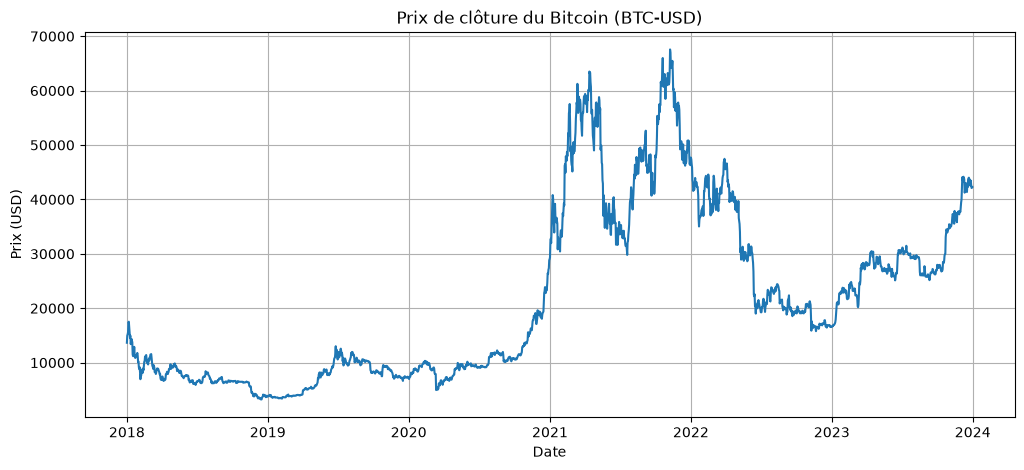

In [10]:
# TODO : tracer l'évolution des prix
plt.plot(price)

plt.title("Prix de clôture du Bitcoin (BTC-USD)")
plt.xlabel("Date")
plt.ylabel("Prix (USD)")

plt.grid(True)

plt.show()

## Question 2

 **Réponses**

**1. Le prix du Bitcoin semble-t-il stationnaire ?**
Non, pas du tout. Sa moyenne et son amplitude changent radicalement selon les périodes : environ 3 000-4 000 $ fin 2018, un pic proche de **69 000 $ en novembre 2021**, une rechute vers **16 000 $ fin 2022**, puis une remontée vers 42 000 $ fin 2023.

**2. Observe-t-on une tendance globale ?**
Une tendance haussière sur le long terme, mais surtout une succession de **cycles très marqués** : krach de 2018 (−80 % depuis le sommet de fin 2017), forte hausse 2020-2021, krach de 2022 (effondrement de Terra/Luna en mai, faillite de FTX en novembre), reprise en 2023.

**3. Pourquoi cela peut-il compliquer la modélisation ?**
- Un modèle entraîné sur une plage de prix ne sait pas extrapoler à une plage qu'il n'a jamais vue (en particulier les arbres de décision, qui prédisent des constantes par morceaux).
- Les relations statistiques changent entre phases haussières, baissières et calmes (**changements de régime**) : ce qui est appris dans une phase peut être faux dans la suivante.
- Toute variable exprimée en dollars (comme le momentum $P_t - P_{t-5}$) change d'échelle avec le prix.

**4. Quel lien peut-on faire avec le TP2 ?**
C'est le même constat que pour le SPY, en plus extrême : les prix sont **non stationnaires** (racine unitaire, test ADF non rejeté), d'où la nécessité de travailler sur les **rendements**. On s'attend aussi à retrouver le **clustering de volatilité** observé avec GARCH.

In [11]:
# TODO : construire les rendements journaliers
returns = price.pct_change()

returns = returns.dropna()

In [12]:
# TODO : afficher les premières lignes des rendements
returns.head()

Date
2018-01-02    0.097011
2018-01-03    0.014611
2018-01-04    0.026196
2018-01-05    0.117333
2018-01-06    0.005594
Name: Close, dtype: float64

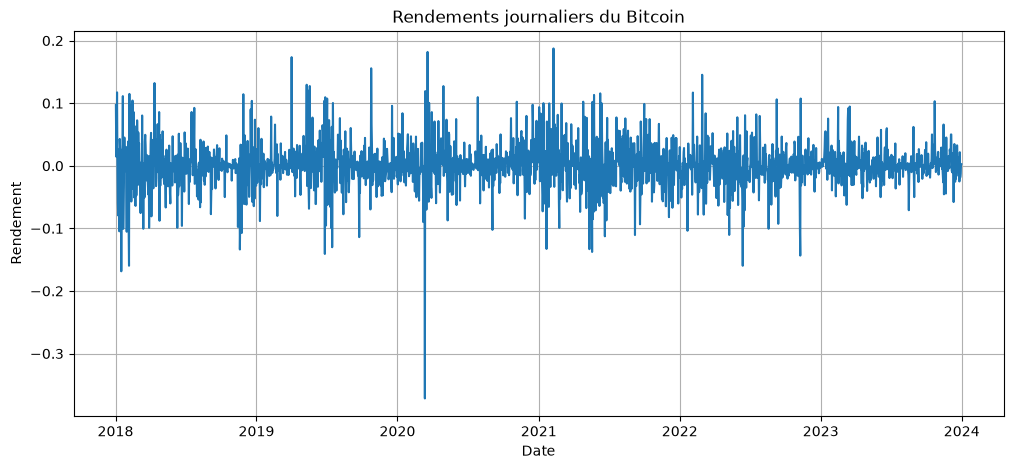

In [13]:
# TODO : tracer les rendements journaliers
plt.plot(returns)

plt.title("Rendements journaliers du Bitcoin")
plt.xlabel("Date")
plt.ylabel("Rendement")

plt.grid(True)

plt.show()

## Question 3

 **Réponses**

**1. Quelle série semble présenter davantage de stabilité ?**
Les **rendements** : ils oscillent autour de 0 sur toute la période, sans tendance, alors que les prix varient d'un facteur 20.

**2. Pourquoi les rendements sont-ils souvent plus adaptés aux modèles temporels ?**
Ils sont proches de la **stationnarité** (moyenne stable autour de 0, échelle comparable dans le temps) : une relation apprise sur 2018-2022 a une chance de rester valable en 2023. Ils sont sans unité, donc comparables entre périodes et entre actifs.

**3. Observe-t-on des périodes de forte volatilité ?**
Oui : fin 2018 (krach du Bitcoin), **mars 2020** (krach du Covid, environ −37 % en une journée le 12 mars), 2021 (bulle puis forte baisse en mai), mai et novembre 2022 (Terra/Luna, FTX). À l'inverse, 2023 est plutôt calme. Les fortes variations arrivent **en grappes**.

**4. Pourquoi cela peut-il compliquer la prévision ?**
- Le niveau de **bruit change** dans le temps : en période agitée, l'erreur de n'importe quel modèle explose.
- Les quelques journées extrêmes **pèsent énormément** dans l'apprentissage (surtout avec une perte au carré comme la MSE) et dans l'évaluation.
- Un modèle entraîné sur une période agitée et testé sur une période calme (ou l'inverse) voit une distribution différente : ses performances dépendent beaucoup de la **période de test**.

In [14]:
# TODO : moyenne et écart-type des rendements
mean_return = returns.mean()

std_return = returns.std()

print("Moyenne :", mean_return)

print("Écart-type :", std_return)

# Bonus : version annualisée (le Bitcoin cote 365 jours par an)
print("Volatilité annualisée : {:.0%}".format(std_return * np.sqrt(365)))
print("Rapport écart-type / moyenne :", round(std_return / mean_return, 1))

Moyenne : 0.0011862039796134486
Écart-type : 0.03633177360816678
Volatilité annualisée : 69%
Rapport écart-type / moyenne : 30.6


## Question 4

 **Réponses**

**1. La moyenne des rendements semble-t-elle proche de zéro ?**
Oui, en valeur journalière : de l'ordre de **0,1-0,2 % par jour**. Elle est positive (le Bitcoin a monté sur la période) mais **environ 20 à 30 fois plus petite que l'écart-type** : au jour le jour, elle est noyée dans le bruit.

**2. Comment interpréter l'écart-type ?**
Environ **3,5-4 % par jour** : c'est l'amplitude typique d'une variation journalière. Un jour « ordinaire », le Bitcoin bouge de ±3-4 %, et des variations de ±10 % arrivent régulièrement. Annualisé, cela donne une volatilité de l'ordre de **65-75 % par an**.

**3. Le Bitcoin présente-t-il une forte volatilité ?**
Oui, très forte : environ **3 à 4 fois** celle du S&P 500 étudié au TP2 (≈ 1,1-1,2 % par jour, ≈ 18 % par an).

**4. Pourquoi cela peut-il rendre la prévision difficile ?**
Plus l'écart-type est grand devant le signal (la moyenne ou la petite partie prévisible), plus le **rapport signal sur bruit** est faible. Un modèle doit extraire un signal de quelques dixièmes de pourcent au milieu de variations de plusieurs pourcents : il risque d'apprendre le bruit (surapprentissage), et l'erreur de prévision reste forcément de l'ordre de l'écart-type.

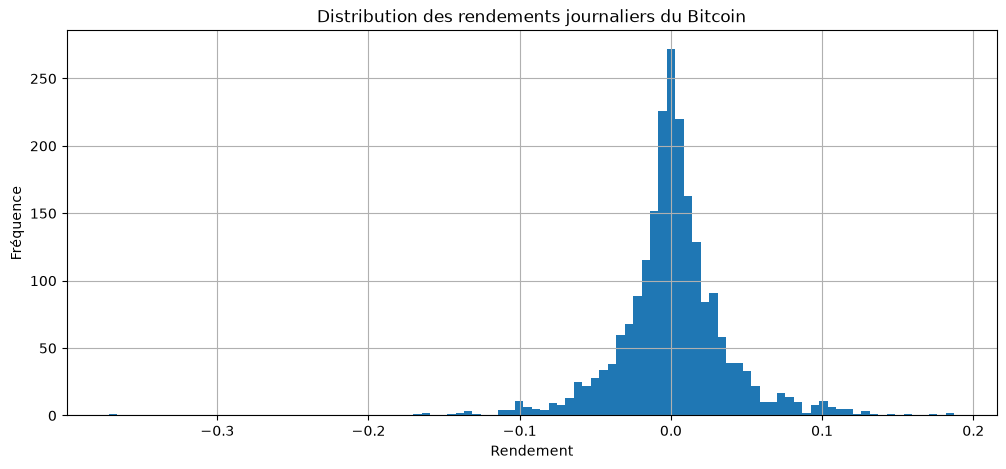

Asymétrie (skewness)  : -0.37
Kurtosis en excès     : 7.93 (0 pour une loi normale)
Pire jour     : 2020-03-12 -37.2%
Meilleur jour : 2021-02-08 18.7%


In [15]:
# TODO : histogramme des rendements
plt.hist(returns, bins=100)

plt.title("Distribution des rendements journaliers du Bitcoin")

plt.xlabel("Rendement")
plt.ylabel("Fréquence")

plt.grid(True)

plt.show()

# Bonus : mesures de forme et extrêmes
print("Asymétrie (skewness)  :", round(returns.skew(), 2))
print("Kurtosis en excès     :", round(returns.kurt(), 2), "(0 pour une loi normale)")
print("Pire jour     :", returns.idxmin().date(), f"{returns.min():.1%}")
print("Meilleur jour :", returns.idxmax().date(), f"{returns.max():.1%}")

## Question 5

 **Réponses**

**1. La distribution semble-t-elle parfaitement symétrique ?**
Non. Elle est centrée près de 0 et en cloche, mais avec un pic central plus pointu qu'une loi normale et une **queue gauche** marquée par quelques krachs très violents (asymétrie souvent négative).

**2. Observe-t-on des valeurs extrêmes ?**
Oui, des **queues épaisses** (kurtosis en excès nettement supérieure à 0) : des journées autour de **−37 % (12 mars 2020)**, et plusieurs journées à ±15-20 %. Avec une loi normale d'écart-type ≈ 3,7 %, une baisse de 37 % (≈ 10 écarts-types) serait pratiquement impossible.

**3. Pourquoi ces événements extrêmes sont-ils importants en finance ?**
Ils concentrent les **pertes les plus lourdes** : une seule journée peut effacer des mois de gains, provoquer des liquidations en chaîne (positions à effet de levier) et des faillites. Les modèles de risque fondés sur la loi normale sous-estiment leur fréquence.

**4. Pourquoi peuvent-ils perturber un modèle de machine learning ?**
- Avec une perte au carré (MSE), une erreur de 30 % pèse autant que **900** erreurs de 1 % : quelques jours extrêmes dominent l'apprentissage, et le modèle se déforme pour essayer de les « expliquer ».
- Ces événements sont **rares et non reproductibles** : le modèle peut apprendre des règles ad hoc (par exemple, « après telle combinaison de features, chute de 30 % ») qui ne généralisent pas.
- Ils dominent aussi l'**évaluation** : la MSE de test peut changer du tout au tout selon qu'un krach tombe ou non dans la période de test.
- Les **réseaux de neurones** sont sensibles aux valeurs extrêmes dans les entrées (gradients instables), d'où l'importance de la normalisation.

---
# PARTIE 3 — Transformer une série temporelle en problème supervisé

 **Concept**

Un modèle comme le Random Forest prend un **tableau** : chaque ligne est un exemple indépendant, chaque colonne une variable. Il n'a aucune notion d'ordre entre les lignes. Pour lui donner « la mémoire », on met le passé **dans les colonnes** :

| date | lag_1 = $r_{t-1}$ | lag_2 = $r_{t-2}$ | … | target = $r_{t+1}$ |
|---|---|---|---|---|
| t | rendement d'hier | rendement d'avant-hier | … | rendement de demain |

C'est la technique de la **fenêtre glissante** (*sliding window*) : la série devient un problème de régression classique $y = f(x)$.

## Question 6

 **Réponses**

**1. Pourquoi les retards représentent-ils le passé ?**
Un retard `shift(k)` place sur la ligne $t$ la valeur observée au temps $t-k$. Sur chaque ligne, `lag_1` contient donc le rendement de la veille, `lag_5` celui d'il y a 5 jours : des informations **déjà connues** au moment de prédire.

**2. Pourquoi la cible doit-elle représenter le futur ?**
Parce que c'est précisément ce que l'on veut prévoir : la valeur **inconnue** au temps $t$. Si la cible était au même instant que les features (ou dans le passé), le modèle décrirait le présent au lieu de prévoir. `shift(-1)` place sur la ligne $t$ le rendement de $t+1$.

**3. Pourquoi un modèle de machine learning ne voit-il pas directement le temps ?**
Les modèles classiques (Random Forest, MLP, régression linéaire) traitent chaque ligne comme un exemple **indépendant** et **interchangeable** : si on mélange les lignes, ils apprennent exactement la même chose. Ils n'ont ni mémoire ni notion de « avant » ou « après ». Toute l'information temporelle doit donc être **encodée dans les features** (retards, fenêtres glissantes). C'est la différence avec ARIMA, ou avec les réseaux séquentiels (RNN, LSTM) qui traitent la séquence dans l'ordre.

**4. Quel lien avec le CM1 et la fonction $f : X \to Y$ ?**
Le machine learning supervisé cherche une fonction $f$ qui associe des entrées $X$ à une sortie $Y$, à partir d'exemples $(x_i, y_i)$. Ici :
- $X$ = le passé résumé en un vecteur : $x_t = (r_{t-1}, r_{t-2}, r_{t-5}, \text{moyenne glissante}, \text{volatilité}, \dots)$ ;
- $Y$ = le futur : $y_t = r_{t+1}$ ;
- on cherche $f$ telle que $r_{t+1} \approx f(x_t)$.

Construire $X$ revient à choisir la **représentation** $\varphi$ du passé (feature engineering). La qualité du modèle dépend autant de cette représentation que de l'algorithme choisi pour $f$.

---
# PARTIE 4 — Construction des features temporelles

Règle à vérifier pour chaque feature : **est-elle connue à la clôture du jour $t$, au moment où l'on prédit $r_{t+1}$ ?**

In [16]:
# TODO : dataframe de travail
df = data.copy()

df["return"] = df["Close"].pct_change()

## Retards temporels

Exemple : $lag_1(t) = r_{t-1}$ : cette variable contient le rendement observé la veille.

In [17]:
# TODO : construire lag_1, lag_2, lag_5
df["lag_1"] = df["return"].shift(1)

df["lag_2"] = df["return"].shift(2)

df["lag_5"] = df["return"].shift(5)

In [18]:
# TODO : afficher quelques lignes
df[["return", "lag_1", "lag_2", "lag_5"]].head(8)

Price,return,lag_1,lag_2,lag_5
Date,,,,
2018-01-01,NaN,NaN,NaN,NaN
2018-01-02,0.097011,NaN,NaN,NaN
2018-01-03,0.014611,0.097011,NaN,NaN
2018-01-04,0.026196,0.014611,0.097011,NaN
2018-01-05,0.117333,0.026196,0.014611,NaN
2018-01-06,0.005594,0.117333,0.026196,NaN
2018-01-07,-0.059873,0.005594,0.117333,0.097011
2018-01-08,-0.079350,-0.059873,0.005594,0.014611


 **Vérification visuelle** : la valeur de `return` d'une ligne réapparaît dans `lag_1` à la ligne suivante, dans `lag_2` deux lignes plus bas et dans `lag_5` cinq lignes plus bas. Les premières lignes contiennent des `NaN` (il n'y a pas encore de passé) : elles seront supprimées plus tard.

## Question 7

 **Pourquoi ces variables peuvent-elles contenir une information utile ?**
Si la série a une **mémoire**, le passé récent renseigne sur le futur proche :
- une autocorrélation positive (**momentum**) : une hausse tend à être suivie d'une hausse ;
- une autocorrélation négative (**retour à la moyenne**) : après une forte hausse, une correction ;
- plus généralement, des **effets non linéaires** qu'un Random Forest peut capter : par exemple, après une très forte chute, la probabilité d'un fort rebond augmente (forte volatilité dans les deux sens).

Le Bitcoin, marché plus spéculatif et moins efficient que le S&P 500, peut présenter un peu plus de ces effets. Mais au TP2 on a vu que l'autocorrélation des rendements est en général **très faible** : ces variables contiennent au mieux un signal ténu. Le choix de `lag_5` permet de tester une dépendance à l'échelle d'une semaine.

## Moyenne glissante

 `rolling(window=5).mean()` calcule, sur chaque ligne $t$, la moyenne de $r_t, r_{t-1}, \dots, r_{t-4}$. Elle inclut le rendement **du jour** $r_t$ : c'est autorisé, car à la clôture du jour $t$ ce rendement est connu. Ce qui serait interdit, c'est une fenêtre qui inclut $r_{t+1}$ (par exemple avec `center=True`).

In [19]:
# TODO : moyenne glissante sur 5 jours
df["rolling_mean_5"] = df["return"].rolling(window=5).mean()

In [20]:
# TODO : afficher return et rolling_mean_5
df[["return", "rolling_mean_5"]].head(10)

Price,return,rolling_mean_5
Date,,
2018-01-01,NaN,NaN
2018-01-02,0.097011,NaN
2018-01-03,0.014611,NaN
2018-01-04,0.026196,NaN
2018-01-05,0.117333,NaN
2018-01-06,0.005594,0.052149
2018-01-07,-0.059873,0.020772
2018-01-08,-0.079350,0.001980
2018-01-09,-0.037884,-0.010836


## Question 8

 **Quelle limite apparaît lorsque le marché change brutalement ?**
Une moyenne glissante est **en retard** sur le marché (*lag*) : elle résume les 5 derniers jours, donc quand le marché se retourne brutalement, elle reflète encore l'ancienne situation pendant plusieurs jours. Exemple : après une semaine de hausse, un krach de −30 % ne fait baisser la moyenne que de 6 points le premier jour, et l'ancien régime reste « dans la fenêtre » 4 jours de plus.
Inversement, un seul jour extrême **déforme** la moyenne pendant 5 jours entiers, puis la fait chuter brutalement quand il sort de la fenêtre : la variable crée des sauts artificiels. Elle lisse le bruit, mais au prix de la **réactivité**, et elle ne peut pas anticiper un changement de régime.

## Volatilité glissante

In [21]:
# TODO : volatilité glissante sur 5 jours
df["rolling_vol_5"] = df["return"].rolling(window=5).std()

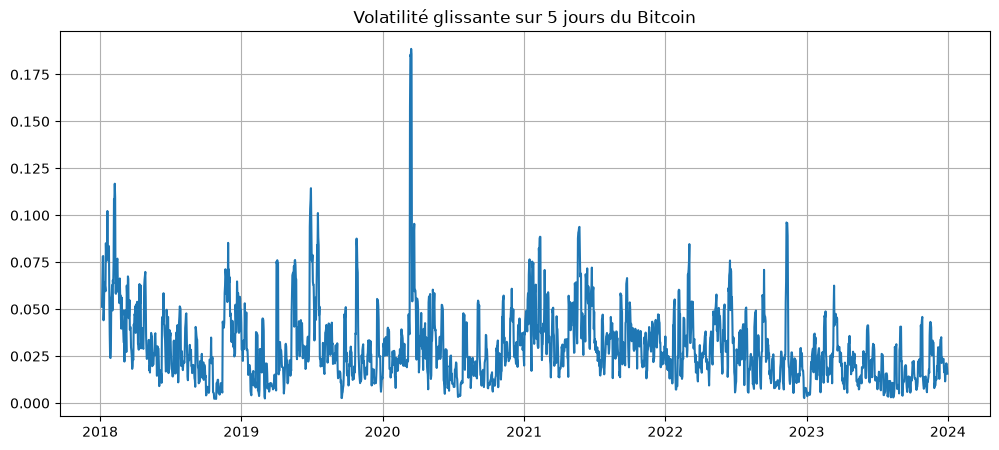

In [22]:
# TODO : tracer la volatilité glissante
plt.plot(df["rolling_vol_5"])

plt.title("Volatilité glissante sur 5 jours du Bitcoin")

plt.grid(True)

plt.show()

## Question 9

 **Réponses**

**1. La volatilité semble-t-elle constante ?**
Non. Elle varie d'environ **1 %** par jour dans les phases calmes (milieu 2023) à **plus de 15-20 %** en mars 2020. Sur 5 jours, l'estimation est aussi très **bruitée** (5 points seulement), d'où les nombreuses pointes.

**2. Observe-t-on des périodes plus agitées ?**
Oui : fin 2018, mars 2020, l'année 2021 (bulle et corrections), mai et juin 2022 (Terra/Luna, faillites de prêteurs crypto comme Celsius), novembre 2022 (FTX). 2023 est nettement plus calme.

**3. Quel lien avec le volatility clustering ?**
Les pics de volatilité ne sont pas isolés : ils forment des **grappes**. Une période agitée dure plusieurs jours ou semaines, puis le calme revient progressivement. C'est exactement le phénomène modélisé par **GARCH** au TP2 : la volatilité a une mémoire, alors que la direction des rendements n'en a presque pas. La volatilité glissante est donc une feature **utile pour prévoir l'amplitude** des mouvements, mais pas forcément leur sens.

**4. Pourquoi cela peut-il compliquer l'apprentissage ?**
- Le **niveau de bruit** de la cible change avec le régime : la même valeur de features peut correspondre à des rendements de ±1 % ou de ±15 % selon la période.
- La perte MSE est dominée par les périodes agitées : le modèle s'ajuste surtout à elles.
- Le régime de la période de test peut différer de celui du train (ici, un test plus calme que la moyenne du train) : les performances mesurées dépendent fortement de la période choisie.
- Connaître la volatilité donne une information sur l'**amplitude** mais pas le **signe** : pour une cible signée comme $r_{t+1}$, cette information est difficile à exploiter.

## Momentum

 Le momentum sur 5 jours est la variation de prix sur une semaine : $P_t - P_{t-5}$.

In [23]:
# TODO : momentum sur 5 jours
df["momentum_5"] = df["Close"] - df["Close"].shift(5)

 **Remarque** : ce momentum est exprimé **en dollars**. Une hausse de 1 000 $ représente +25 % quand le Bitcoin vaut 4 000 $, mais seulement +2 % quand il vaut 50 000 $. La variable n'est donc pas stationnaire et ses valeurs de test peuvent sortir de la plage vue à l'entraînement. Une version relative, $\frac{P_t}{P_{t-5}} - 1$, serait plus robuste (on garde ici la formule de l'énoncé, et on y revient dans l'analyse des importances).

## Question 10

 **Réponses**

**1. Que signifie un momentum positif ?**
Le prix a **monté** sur les 5 derniers jours : le marché est dans une dynamique haussière récente.

**2. Que signifie un momentum négatif ?**
Le prix a **baissé** sur les 5 derniers jours : dynamique baissière récente.

**3. Pourquoi le momentum peut-il être utile ?**
En finance, on observe parfois un effet de **persistance des tendances** : les investisseurs réagissent avec retard aux informations, suivent les tendances, ou achètent par peur de rater la hausse (FOMO), ce qui prolonge les mouvements. Sur un marché spéculatif comme le Bitcoin, porté par l'enthousiasme et l'effet de levier, cet effet peut être plus marqué. Le momentum est aussi un indicateur de **régime** (haussier ou baissier).

**4. Pourquoi cet effet peut-il disparaître ?**
- Dès qu'une régularité est connue et exploitée par de nombreux traders, leurs ordres la font disparaître (**efficience** des marchés).
- Les tendances se **retournent** brutalement (fin de bulle, krach) : c'est justement au moment des retournements que le momentum se trompe le plus.
- L'effet dépend du **régime** de marché : il peut exister en phase de bulle et s'inverser en phase de crise.
- À l'horizon d'un jour, le bruit domine : même un vrai effet de tendance est difficile à exploiter.

## Variation du volume

In [24]:
# TODO : variation relative du volume
df["volume_change"] = df["Volume"].pct_change()

# Sécurité : un volume nul la veille donnerait une division par zéro (infini)
df["volume_change"] = df["volume_change"].replace([np.inf, -np.inf], np.nan)

## Question 11

 **Réponses**

**1. Pourquoi le volume peut-il contenir une information utile ?**
Le volume mesure l'**intensité de l'activité** et l'intérêt des investisseurs. Un mouvement de prix accompagné d'un fort volume est souvent jugé plus « significatif » (beaucoup d'acteurs y participent) qu'un mouvement à faible volume. Le volume est aussi fortement lié à la **volatilité** : les jours agités sont des jours de fort volume.

**2. Pourquoi une variation brutale du volume peut-elle être importante ?**
Elle signale souvent un **événement** : une nouvelle importante, une panique (ventes massives, liquidations en cascade de positions à effet de levier), une phase spéculative (afflux d'acheteurs) ou le début d'un **changement de régime**. C'est un indicateur avancé possible de volatilité.

**3. Pourquoi cette variable reste-t-elle difficile à interpréter ?**
- Un pic de volume ne dit **pas le sens** du mouvement : il peut correspondre à une ruée à l'achat comme à une panique à la vente.
- La variation relative est **très bruitée** et peut prendre des valeurs extrêmes (un jour calme suivi d'un jour actif donne +300 %).
- Le volume a des **effets de calendrier** (souvent plus faible le week-end pour les cryptos) et de structure : les plateformes agrégées par Yahoo Finance changent, et une partie des volumes crypto peut être artificielle (*wash trading*).
- Son lien avec le rendement futur est **instable** dans le temps.

---
# PARTIE 5 — Construction de la cible

In [25]:
# TODO : construire la cible
df["target"] = df["return"].shift(-1)

In [26]:
# TODO : afficher return et target
df[["return", "target"]].head(8)

Price,return,target
Date,,
2018-01-01,NaN,0.097011
2018-01-02,0.097011,0.014611
2018-01-03,0.014611,0.026196
2018-01-04,0.026196,0.117333
2018-01-05,0.117333,0.005594
2018-01-06,0.005594,-0.059873
2018-01-07,-0.059873,-0.079350
2018-01-08,-0.079350,-0.037884


 **Vérification** : la valeur de `target` sur une ligne est égale à la valeur de `return` sur la **ligne suivante**. La dernière ligne a une cible `NaN` (pas de « demain » connu) : elle sera supprimée.

## Question 12

 **Réponses**

**1. Pourquoi utilise-t-on `shift(-1)` pour construire la cible ?**
Pour aligner sur la même ligne les informations disponibles au temps $t$ (les features) et la quantité à prédire au temps $t+1$. Le modèle apprend ainsi la relation « avec ce que je sais aujourd'hui, quel sera le rendement de demain ? ».

**2. Pourquoi cette opération est-elle autorisée pour `target` ?**
Parce que la cible **est** l'information future que l'on cherche à prévoir : pendant l'entraînement, on a besoin de la vraie réponse pour apprendre. Elle n'est jamais donnée au modèle en entrée : en production, c'est précisément la valeur que le modèle doit produire.

**3. Pourquoi ce serait une erreur grave d'utiliser `target` comme feature ?**
Ce serait donner la **réponse** au modèle dans ses entrées : il apprendrait simplement « prédiction = target » et obtiendrait une erreur quasi nulle. C'est une **fuite d'information** totale : le score serait parfait sur le papier, mais le modèle serait **inutilisable** en réalité, car au moment de prédire, $r_{t+1}$ n'existe pas encore. Plus insidieusement, toute variable calculée à partir de `target` ou avec `shift(-k)` (par exemple une moyenne glissante centrée) produit la même fuite, en plus discret.

**4. Quelle question faut-il toujours se poser ?**
« **Cette information était-elle réellement disponible au moment où la prédiction aurait été faite ?** » Pour chaque feature, chaque étape de prétraitement (normalisation, imputation) et chaque choix de découpage des données.

In [27]:
# TODO : supprimer les valeurs manquantes
df = df.dropna()

print("Nombre de lignes après suppression des NaN :", len(df))

Nombre de lignes après suppression des NaN : 2184


---
# PARTIE 6 — Construction du dataset supervisé

In [28]:
# TODO : liste des features
features = [
    "lag_1",
    "lag_2",
    "lag_5",
    "rolling_mean_5",
    "rolling_vol_5",
    "momentum_5",
    "volume_change"
]

In [29]:
# TODO : construire X et y
X = df[features]

y = df["target"]

In [30]:
# TODO : afficher les dimensions
print("Dimensions de X :", X.shape)

print("Dimensions de y :", y.shape)

Dimensions de X : (2184, 7)
Dimensions de y : (2184,)


## Question 13

 **Réponses**

**1. Que représente une ligne de X ?**
Une **date** $t$, décrite par 7 variables qui résument le passé récent du Bitcoin à la clôture de ce jour : les rendements d'hier, d'avant-hier et d'il y a 5 jours, la tendance et la volatilité de la dernière semaine, la variation de prix sur 5 jours et la variation de volume du jour.

**2. Les colonnes de X représentent-elles uniquement le passé ?**
Oui, si on définit le « passé » comme **tout ce qui est connu à la clôture du jour $t$** : les retards ($t-1$, $t-2$, $t-5$), et les fenêtres glissantes, le momentum et la variation de volume qui incluent le jour $t$ lui-même. Aucune colonne n'utilise $t+1$ : pas de `shift(-1)`, pas de fenêtre centrée. La seule colonne qui regarde le futur est `target`, et elle est exclue de `X`.

**3. Que représente y ?**
Le **rendement du lendemain** $r_{t+1}$, la valeur à prédire pour chaque ligne. C'est une variable **continue** : on fait de la **régression**.

**4. Pourquoi peut-on maintenant utiliser un modèle de machine learning classique ?**
Parce que la série temporelle a été transformée en un **tableau classique** $(X, y)$ : chaque ligne est un exemple avec un vecteur d'entrées de taille fixe et une sortie. Toute la dimension temporelle est encodée dans les colonnes. N'importe quel régresseur (Random Forest, MLP, régression linéaire) peut apprendre $y \approx f(X)$. La seule précaution restante concerne la **validation**, qui doit respecter l'ordre du temps.

---
# PARTIE 7 — Validation temporelle

In [31]:
# TODO : split temporel 80 / 20
split = int(len(X) * 0.8)

X_train = X.iloc[:split]

X_test = X.iloc[split:]

y_train = y.iloc[:split]

y_test = y.iloc[split:]

In [32]:
# TODO : afficher les périodes train et test
print("Train :", X_train.index.min().date(), "->", X_train.index.max().date(), f"({len(X_train)} jours)")

print("Test  :", X_test.index.min().date(), "->", X_test.index.max().date(), f"({len(X_test)} jours)")

# Bonus : la volatilité de la cible n'est pas la même sur les deux périodes
print("Écart-type de la cible  train : {:.2%} | test : {:.2%}".format(y_train.std(), y_test.std()))

Train : 2018-01-07 -> 2022-10-19 (1747 jours)
Test  : 2022-10-20 -> 2023-12-30 (437 jours)
Écart-type de la cible  train : 3.86% | test : 2.42%


## Question 14

 **Réponses**

**1. Pourquoi le train doit-il être situé avant le test ?**
Pour **simuler la réalité** : le jour où l'on utilise le modèle, on ne dispose que du passé et on prédit le futur. Le test doit donc être une période **jamais vue et postérieure** à l'entraînement. Ici, le modèle apprend sur 2018 - fin 2022 environ et il est évalué sur 2023 environ, une période réellement « future » pour lui.

**2. Pourquoi un split aléatoire peut-il être dangereux ?**
- Le modèle s'entraînerait sur des jours **postérieurs** aux jours de test : il apprendrait avec des informations du futur (*look-ahead bias*).
- Des jours **voisins** se retrouveraient de part et d'autre : leurs features se recouvrent fortement (les fenêtres de 5 jours partagent 4 jours) et ils appartiennent au même **régime de volatilité**. Le test serait « déjà vu » en partie.
- Train et test auraient la même distribution (mêmes crises, mêmes régimes), ce qui masque le vrai problème : **généraliser à une période nouvelle**, éventuellement d'un régime différent.

Le résultat serait un score trop optimiste. On le vérifie expérimentalement à la partie 12.

---
# PARTIE 8 — Modèle statistique de référence : ARIMA

 **Concept** : ARIMA(1, 0, 1) sur les rendements : $r_t = c + \varphi_1 r_{t-1} + \varepsilon_t + \theta_1 \varepsilon_{t-1}$ (rappel du TP2).

**Choix des séries pour une comparaison équitable** : les modèles de ML sont évalués sur `y_test`, c'est-à-dire les rendements $r_{t+1}$ des dates de test. Pour comparer ARIMA sur **exactement les mêmes rendements**, on l'entraîne sur la série `y_train` (les rendements jusqu'au début du test) et on le compare à `y_test`. Ce sont bien des rendements, avec le même split temporel, et sans fuite : le dernier rendement vu par ARIMA est celui qui précède immédiatement la période de test.

 **Piège rencontré au TP2** : avec des dates sans fréquence régulière, les versions récentes de statsmodels refusent de prévoir (`No supported index is available`). On estime donc le modèle sur un index numéroté et on remet les dates ensuite.

In [33]:
# TODO : séries train et test pour ARIMA (rendements, même split temporel)
returns_train = y_train

returns_test = y_test

In [34]:
# TODO : construire et entraîner ARIMA(1,0,1)
model_arima = ARIMA(returns_train.reset_index(drop=True), order=(1, 0, 1))

result_arima = model_arima.fit()

print(result_arima.summary().tables[1])   # tableau des coefficients

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0008      0.001      0.935      0.350      -0.001       0.003
ar.L1         -0.4434      0.273     -1.625      0.104      -0.978       0.092
ma.L1          0.3854      0.280      1.376      0.169      -0.164       0.934
sigma2         0.0015   2.36e-05     62.871      0.000       0.001       0.002


In [35]:
# TODO : prévisions ARIMA sur toute la période de test
pred_arima = result_arima.forecast(steps=len(returns_test))

pred_arima.index = returns_test.index   # on remet les dates
pred_arima.head()

Date
2022-10-20    0.001039
2022-10-21    0.000750
2022-10-22    0.000878
2022-10-23    0.000822
2022-10-24    0.000847
Name: predicted_mean, dtype: float64

In [36]:
# TODO : MSE et MAE
mse_arima = mean_squared_error(returns_test, pred_arima)

mae_arima = mean_absolute_error(returns_test, pred_arima)

print("MSE ARIMA :", mse_arima)

print("MAE ARIMA :", mae_arima)

MSE ARIMA : 0.0005864528755490632
MAE ARIMA : 0.015720817558426126


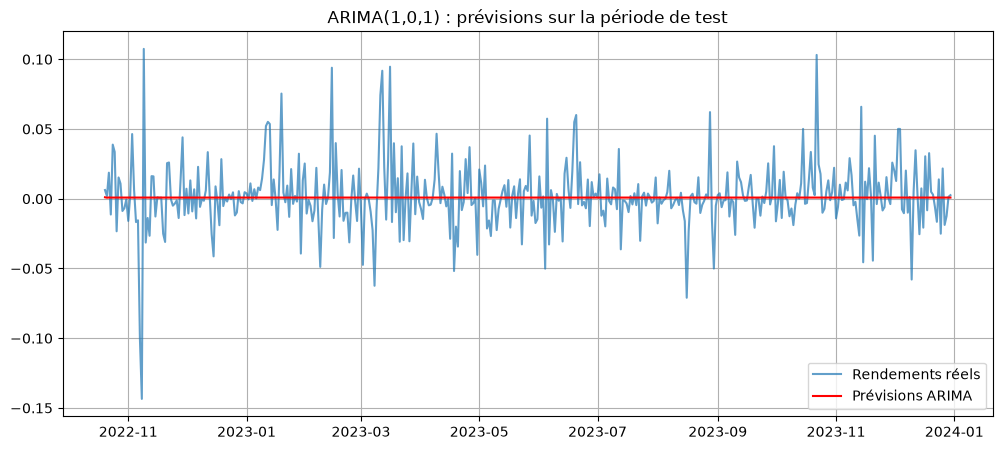

In [37]:
# TODO : tracer les rendements réels et les prévisions ARIMA
plt.plot(returns_test.index, returns_test, label="Rendements réels", alpha=0.7)

plt.plot(pred_arima.index, pred_arima, label="Prévisions ARIMA", color="red")

plt.title("ARIMA(1,0,1) : prévisions sur la période de test")
plt.legend()

plt.grid(True)

plt.show()

 **Références naïves (indispensables pour juger les MSE)**

Une MSE seule ne veut rien dire : il faut la comparer à des prédicteurs triviaux, sur la même période :
- **prédire 0** (« demain, pas de variation ») ;
- **prédire la moyenne du train** (le rendement moyen historique).

On calcule aussi un **$R^2$ hors échantillon** : $R^2 = 1 - \frac{\text{MSE}_{\text{modèle}}}{\text{MSE}_{\text{prédire la moyenne}}}$. S'il est **négatif**, le modèle fait **pire** que prédire la moyenne historique.

In [38]:
pred_zero = pd.Series(0.0, index=y_test.index)
pred_mean = pd.Series(y_train.mean(), index=y_test.index)

mse_zero, mae_zero = mean_squared_error(y_test, pred_zero), mean_absolute_error(y_test, pred_zero)
mse_mean, mae_mean = mean_squared_error(y_test, pred_mean), mean_absolute_error(y_test, pred_mean)

def r2_oos(mse_model):
    return 1 - mse_model / mse_mean

print(f"Prédire 0          : MSE = {mse_zero:.6f} | MAE = {mae_zero:.5f}")
print(f"Prédire la moyenne : MSE = {mse_mean:.6f} | MAE = {mae_mean:.5f}")
print(f"ARIMA multi-pas    : MSE = {mse_arima:.6f} | MAE = {mae_arima:.5f} | R² hors échantillon = {r2_oos(mse_arima):+.4f}")

Prédire 0          : MSE = 0.000589 | MAE = 0.01569
Prédire la moyenne : MSE = 0.000586 | MAE = 0.01572
ARIMA multi-pas    : MSE = 0.000586 | MAE = 0.01572 | R² hors échantillon = -0.0000


 **Bonus : ARIMA à un pas glissant (comparaison équitable avec le ML)**

`forecast(steps=…)` prédit toute la période de test **en une fois, depuis la fin du train**, sans voir les rendements de test : la prévision converge vers la moyenne en quelques jours (ligne plate). Or le Random Forest et le MLP, eux, reçoivent **chaque jour** les vrais retards récents. Pour comparer à armes égales, on fait une prévision **à un pas** : mêmes paramètres (estimés sur le train), mais chaque prévision utilise les vrais rendements jusqu'à la veille.

In [39]:
full_series = pd.concat([returns_train, returns_test]).reset_index(drop=True)
pred_arima_1step = result_arima.apply(full_series).get_prediction(start=len(returns_train)).predicted_mean
pred_arima_1step = pd.Series(np.asarray(pred_arima_1step), index=returns_test.index)

mse_arima_1step = mean_squared_error(returns_test, pred_arima_1step)
mae_arima_1step = mean_absolute_error(returns_test, pred_arima_1step)
print(f"ARIMA un pas       : MSE = {mse_arima_1step:.6f} | MAE = {mae_arima_1step:.5f} | R² hors échantillon = {r2_oos(mse_arima_1step):+.4f}")

ARIMA un pas       : MSE = 0.000589 | MAE = 0.01564 | R² hors échantillon = -0.0044


## Question 15

 **Réponses**

**1. Les prévisions ARIMA suivent-elles précisément les rendements réels ?**
Non. La prévision multi-pas devient une **ligne quasi plate** au bout de quelques jours, proche du rendement moyen du train, alors que les vrais rendements oscillent de ±2 à ±10 %. Même en prévision à un pas, les prévisions restent minuscules par rapport aux mouvements réels. Les MSE et MAE d'ARIMA sont pratiquement identiques à celles des références naïves (« prédire 0 » ou « prédire la moyenne »), avec un $R^2$ hors échantillon proche de 0.

**2. Quelle hypothèse importante est faite par ARIMA ?**
- **Linéarité** : le rendement futur est une combinaison linéaire des rendements et des chocs passés.
- **Stationnarité** et **stabilité des paramètres** : la même dynamique (mêmes coefficients) s'applique sur toute la période, de 2018 à 2023.
- Des chocs de **variance constante** (homoscédasticité), alors que la volatilité du Bitcoin varie énormément (voir TP2 : c'est le rôle de GARCH).
- Le modèle est **univarié** : il n'utilise que le passé de la série elle-même, pas le volume ou d'autres informations.

**3. Quelle peut être la limite principale d'un modèle linéaire comme celui-ci ?**
Il ne peut capter que des **dépendances linéaires** (autocorrélations), qui sont quasi nulles pour les rendements. Il ne peut pas représenter des effets **non linéaires** ou **conditionnels** : par exemple, « après une très forte chute en période de forte volatilité, le rebond est plus probable », des effets de seuil, des interactions entre volume et volatilité, ou des comportements différents selon le régime. C'est précisément ce que les modèles de ML (Random Forest, réseau de neurones) peuvent tenter de capturer.

---
# PARTIE 9 — Random Forest sur features temporelles

 Rappel (TP1) : un Random Forest moyenne 300 arbres de décision entraînés sur des échantillons bootstrap. En régression, chaque feuille prédit la **moyenne** des cibles qu'elle contient, et la forêt moyenne les arbres. `max_depth=5` limite la complexité de chaque arbre pour éviter de mémoriser le bruit.

In [40]:
# TODO : construire un RandomForestRegressor
model_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    random_state=42
)

In [41]:
# TODO : entraîner le modèle
model_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

In [42]:
# TODO : prédictions du Random Forest
pred_rf = model_rf.predict(X_test)

In [43]:
# TODO : MSE et MAE, comparaison avec ARIMA
mse_rf = mean_squared_error(y_test, pred_rf)

mae_rf = mean_absolute_error(y_test, pred_rf)

print("MSE Random Forest :", mse_rf, " | ARIMA :", mse_arima)

print("MAE Random Forest :", mae_rf, " | ARIMA :", mae_arima)

print(f"R² hors échantillon Random Forest : {r2_oos(mse_rf):+.4f}")

MSE Random Forest : 0.0005863629429093306  | ARIMA : 0.0005864528755490632
MAE Random Forest : 0.0159004043046016  | ARIMA : 0.015720817558426126
R² hors échantillon Random Forest : +0.0002


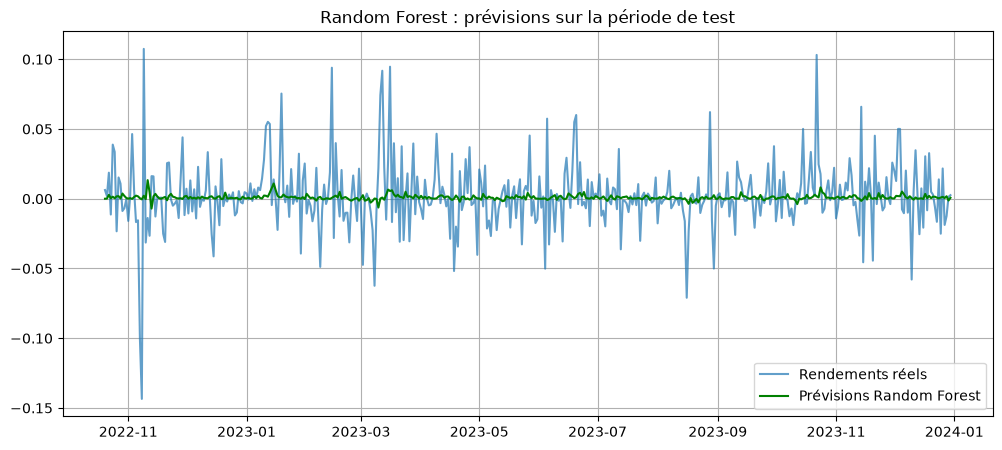

In [44]:
# TODO : tracer les rendements réels et les prévisions du Random Forest
plt.plot(y_test.index, y_test, label="Rendements réels", alpha=0.7)

plt.plot(y_test.index, pred_rf, label="Prévisions Random Forest", color="green")

plt.title("Random Forest : prévisions sur la période de test")
plt.legend()

plt.grid(True)

plt.show()

 **Analyse des prévisions** : les prévisions du Random Forest varient davantage que celles d'ARIMA, mais restent **très resserrées autour de 0** (quelques dixièmes de pourcent) par rapport aux vrais rendements. C'est le comportement attendu d'un modèle de régression quand le signal est faible : minimiser la MSE pousse à prédire des valeurs proches de la moyenne, car prédire des mouvements amples serait très pénalisé lorsqu'ils sont dans le mauvais sens. Les plus grands écarts de prévision apparaissent souvent après des journées extrêmes : le modèle a appris quelques règles sur les épisodes de forte volatilité du train.

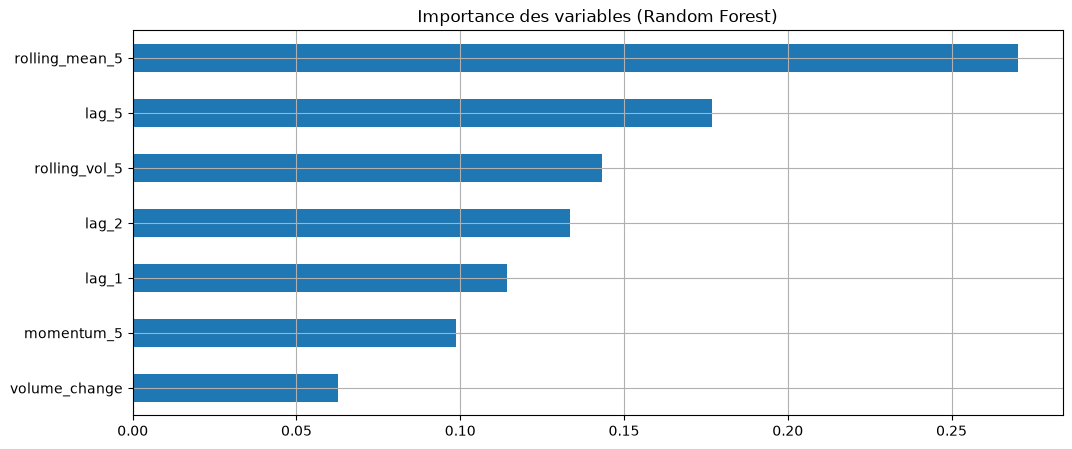

rolling_mean_5    0.270
lag_5             0.177
rolling_vol_5     0.143
lag_2             0.134
lag_1             0.114
momentum_5        0.099
volume_change     0.063
dtype: float64

In [45]:
# TODO : importance des variables
importance = pd.Series(model_rf.feature_importances_, index=features)

importance.sort_values().plot(kind="barh", title="Importance des variables (Random Forest)")
plt.grid(True)
plt.show()

importance.sort_values(ascending=False).round(3)

## Question 17

 **Quelles variables semblent les plus importantes ?** (à adapter à ton graphique)

En général, les variables les plus « importantes » sont celles liées à l'**amplitude des mouvements** et aux épisodes extrêmes : `rolling_vol_5`, `momentum_5`, `volume_change` et les retards (`lag_1`, `lag_5`) dans une moindre mesure.

Mais il faut interpréter ces importances avec beaucoup de prudence :
- L'importance mesure la **réduction d'erreur sur le train** permise par les découpages sur une variable (importance par impureté). Elle dit à quoi le modèle **s'est fié**, pas si cette variable **prédit réellement** le futur. Quand le modèle surapprend, les importances reflètent surtout ce qui a permis de **mémoriser le bruit**.
- Elle est **biaisée** en faveur des variables continues avec beaucoup de valeurs distinctes et de valeurs extrêmes (volatilité, variation de volume), qui offrent beaucoup de seuils possibles pour isoler quelques jours exceptionnels.
- `momentum_5` est en dollars : son échelle change avec le prix, donc ses seuils appris sur le train correspondent à des situations différentes en test.
- Une variable importante peut l'être uniquement à cause de **quelques journées extrêmes** du train (mars 2020, mai 2021, juin et novembre 2022).

Une méthode plus fiable consiste à calculer une **importance par permutation sur le jeu de test** (`sklearn.inspection.permutation_importance`) : on mélange une variable et on regarde si l'erreur **de test** augmente. Si les importances par permutation sont proches de 0, aucune variable n'apporte d'information réellement exploitable hors échantillon.

In [ ]:
# Bonus : importance par permutation sur le TEST (ce qui compte vraiment pour la prévision)
from sklearn.inspection import permutation_importance

perm = permutation_importance(model_rf, X_test, y_test, n_repeats=20, random_state=42,
                              scoring="neg_mean_squared_error")
pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)

---
# PARTIE 10 — Réseau de neurones dense

## Normalisation des données

 **Pourquoi normaliser ?** Les features ont des échelles très différentes : `lag_1` ≈ 0,03, `momentum_5` ≈ plusieurs milliers de dollars, `volume_change` peut valoir 3. Un réseau de neurones calcule des combinaisons $w^\top x$ et apprend par descente de gradient : sans normalisation, les variables de grande échelle dominent les gradients et l'apprentissage est instable. Le `StandardScaler` transforme chaque variable en $\frac{x - \mu}{\sigma}$ (moyenne 0, écart-type 1).

**Point fondamental : le scaler est ajusté sur le train uniquement.** La moyenne $\mu$ et l'écart-type $\sigma$ font partie du modèle. Les calculer sur tout le dataset ferait entrer des statistiques de la période de test (par exemple son niveau de prix ou de volatilité) dans l'entraînement : c'est une **fuite d'information**. On applique ensuite (`transform`) les mêmes $\mu$ et $\sigma$ au test.

In [46]:
# TODO : construire un StandardScaler
scaler = StandardScaler()

In [47]:
# TODO : ajuster le scaler sur le train uniquement
scaler.fit(X_train)

StandardScaler()

In [48]:
# TODO : transformer X_train et X_test
X_train_scaled = scaler.transform(X_train)

X_test_scaled = scaler.transform(X_test)

# Vérification : sur le train, moyennes ≈ 0 et écarts-types ≈ 1 ; sur le test, pas exactement
print("Moyennes test après normalisation :", X_test_scaled.mean(axis=0).round(2))

Moyennes test après normalisation : [ 0.03  0.03  0.03  0.07 -0.64  0.11  0.15]


 Sur le test, les moyennes ne sont **pas** exactement 0 : c'est normal et c'est même le signe que l'on n'a pas triché. Le test vient d'une autre période, avec une distribution différente (par exemple `momentum_5` en dollars).

## Réseau de neurones

 `MLPRegressor` = perceptron multicouche : deux couches cachées (64 puis 32 neurones, activation ReLU) et une sortie linéaire. `early_stopping=True` réserve 10 % du train comme validation et arrête l'entraînement quand le score de validation ne s'améliore plus (limite le surapprentissage).

 Subtilité : dans scikit-learn, ces 10 % de validation sont tirés **au hasard** dans le train, pas à la fin. Ce n'est pas une fuite vers le test, mais ce n'est pas une validation strictement temporelle.

In [49]:
# TODO : construire un MLPRegressor
model_mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    early_stopping=True,
    random_state=42
)

In [50]:
# TODO : entraîner le réseau sur les données normalisées
model_mlp.fit(X_train_scaled, y_train)

print("Nombre d'itérations avant arrêt :", model_mlp.n_iter_)

Nombre d'itérations avant arrêt : 109


In [51]:
# TODO : prédictions du réseau
pred_mlp = model_mlp.predict(X_test_scaled)

In [52]:
# TODO : MSE et MAE
mse_mlp = mean_squared_error(y_test, pred_mlp)

mae_mlp = mean_absolute_error(y_test, pred_mlp)

print("MSE MLP :", mse_mlp)

print("MAE MLP :", mae_mlp)

print(f"R² hors échantillon MLP : {r2_oos(mse_mlp):+.4f}")

MSE MLP : 0.0010985424314671809
MAE MLP : 0.024439281129437898
R² hors échantillon MLP : -0.8732


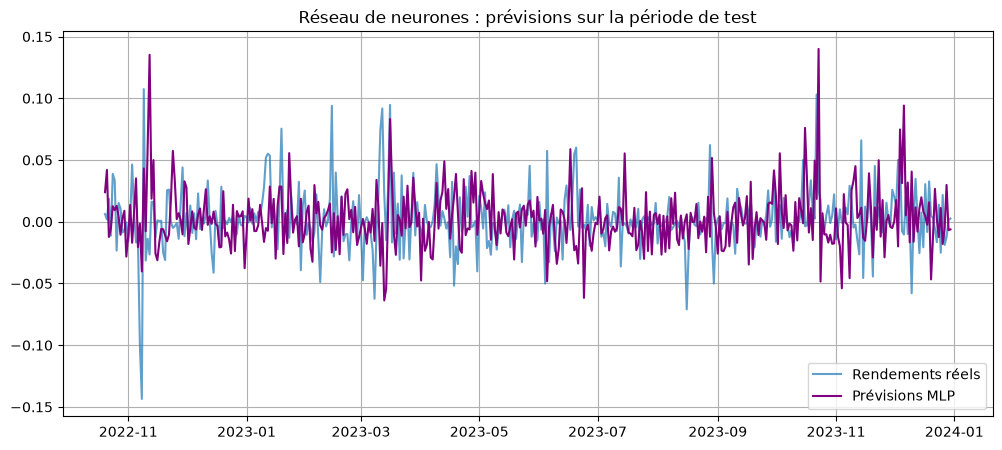

In [53]:
# TODO : tracer les rendements réels et les prévisions du réseau
plt.plot(y_test.index, y_test, label="Rendements réels", alpha=0.7)

plt.plot(y_test.index, pred_mlp, label="Prévisions MLP", color="purple")

plt.title("Réseau de neurones : prévisions sur la période de test")
plt.legend()

plt.grid(True)

plt.show()

 **Analyse des prévisions** (à confirmer avec ton graphique) : deux comportements sont fréquents avec un MLP sur ce type de cible :
- des prévisions **plus dispersées** que celles du Random Forest, parfois avec des valeurs aberrantes quand une feature de test sort de la plage du train (le réseau extrapole linéairement, alors qu'un arbre plafonne) ;
- ou au contraire des prévisions presque **constantes**, si l'early stopping arrête l'apprentissage très tôt faute de signal.

Dans les deux cas, la MSE du réseau est rarement meilleure que celle des références naïves : un modèle plus flexible apprend surtout le bruit quand le signal est faible.

---
# PARTIE 11 — Comparaison des modèles

In [54]:
# TODO : tableau comparatif (avec les références naïves, indispensables pour juger)
results = pd.DataFrame({
    "Modèle": ["Prédire 0", "Prédire la moyenne", "ARIMA(1,0,1)", "ARIMA un pas (bonus)", "Random Forest", "MLP"],
    "MSE": [mse_zero, mse_mean, mse_arima, mse_arima_1step, mse_rf, mse_mlp],
    "MAE": [mae_zero, mae_mean, mae_arima, mae_arima_1step, mae_rf, mae_mlp],
})
results["R² hors échantillon"] = 1 - results["MSE"] / mse_mean

results

,Modèle,MSE,MAE,R² hors échantillon
0,Prédire 0,0.000589,0.015691,-4.871076e-03
1,Prédire la moyenne,0.000586,0.015721,0.000000e+00
2,"ARIMA(1,0,1)",0.000586,0.015721,-1.453538e-08
3,ARIMA un pas (bonus),0.000589,0.015640,-4.357080e-03
4,Random Forest,0.000586,0.015900,1.533356e-04
5,MLP,0.001099,0.024439,-8.731982e-01


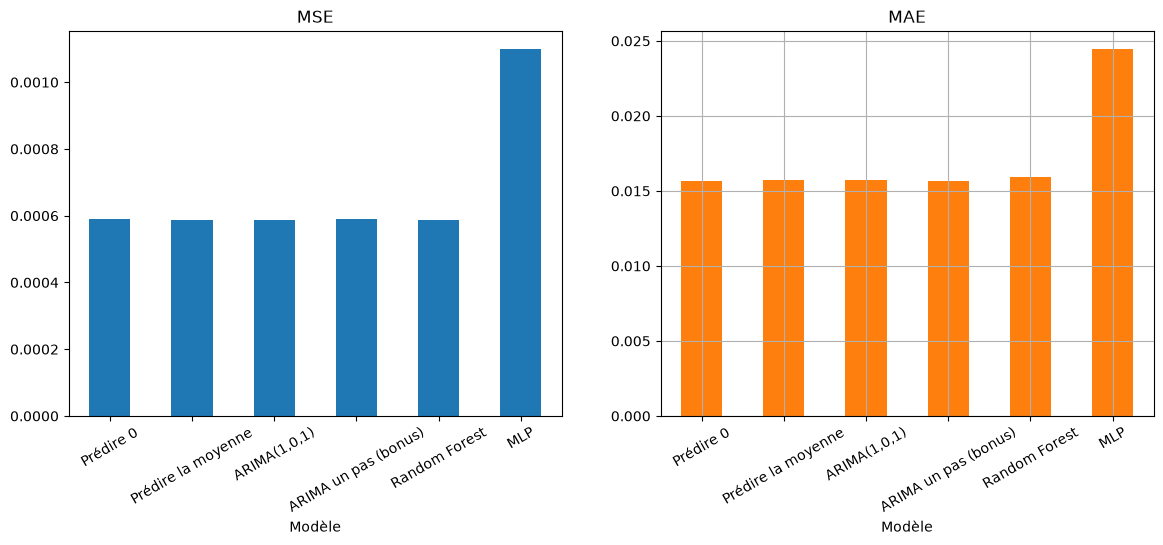

In [55]:
# TODO : comparaison graphique
results.set_index("Modèle")[["MSE", "MAE"]].plot(
    kind="bar",
    subplots=True,
    layout=(1, 2),
    figsize=(14, 5),
    legend=False,
    rot=30
)

plt.grid(True)

plt.show()

 Les barres de MSE sont presque toutes de la même hauteur : c'est déjà une réponse. On trace deux sous-graphiques séparés car la MSE (≈ 10⁻³) et la MAE (≈ 10⁻²) ne sont pas à la même échelle : sur un seul graphique, les barres de MSE seraient invisibles.

## Question 20

 **Réponses** (à adapter avec ton tableau)

**1. Quel modèle semble obtenir les meilleures performances ?**
Sur ce type de données, les erreurs sont **toutes très proches**. Selon l'exécution, c'est souvent une **référence naïve** (prédire 0 ou la moyenne), ARIMA ou le Random Forest peu profond qui obtient la plus petite MSE, tandis que le MLP est souvent un peu moins bon. Le $R^2$ hors échantillon de tous les modèles est **proche de 0, voire négatif** : aucun modèle n'explique une part significative des rendements de test.

À noter : la MAE peut classer les modèles différemment de la MSE. « Prédire 0 » est souvent très bon en MAE, car la médiane des rendements journaliers est proche de 0.

**2. Les différences sont-elles très importantes ?**
Non. Les écarts relatifs de MSE sont de l'ordre de **quelques pourcents**, du même ordre que la variabilité due au hasard (changer la graine du Random Forest, ou décaler la période de test de quelques semaines, peut inverser le classement). La MSE est dominée par quelques journées extrêmes que personne n'a prévues. On ne peut donc **pas conclure** qu'un modèle est réellement supérieur : il faut une validation plus robuste (partie 13). Le message du TP : sur des rendements financiers, même avec des modèles flexibles, la performance reste très limitée, et un petit gain apparent ne prouve pas l'existence d'un vrai signal.

---
# PARTIE 12 — Erreur classique : split aléatoire

 En machine learning classique, on utilise souvent `train_test_split(..., shuffle=True)`. En série temporelle, c'est dangereux : on mélange passé et futur.

In [56]:
# TODO : split aléatoire
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42
)

In [57]:
# TODO : Random Forest sur le split aléatoire
model_random = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42)

model_random.fit(X_train_random, y_train_random)
pred_random = model_random.predict(X_test_random)

mse_random = mean_squared_error(y_test_random, pred_random)

print("MSE Random Forest - split aléatoire :", mse_random)
print("MSE Random Forest - split temporel  :", mse_rf)

MSE Random Forest - split aléatoire : 0.001120757532367734
MSE Random Forest - split temporel  : 0.0005863629429093306


 **Attention, piège d'analyse** : les deux MSE ne sont **pas directement comparables**, car elles sont mesurées sur des jours différents. Le test temporel est surtout 2023, une année plutôt **calme** ; le test aléatoire contient des jours de toutes les années, y compris les crises. Comme la MSE dépend avant tout du niveau de volatilité de la période testée, il faut comparer chaque modèle à **sa propre référence naïve** sur **son propre** jeu de test, via le $R^2$ hors échantillon.

In [58]:
mse_mean_random = mean_squared_error(y_test_random, np.full(len(y_test_random), y_train_random.mean()))

print(f"Split temporel  : R² hors échantillon = {1 - mse_rf / mse_mean:+.4f}")
print(f"Split aléatoire : R² hors échantillon = {1 - mse_random / mse_mean_random:+.4f}")

Split temporel  : R² hors échantillon = +0.0002
Split aléatoire : R² hors échantillon = -0.0321


 **Bonus : une fuite d'information volontaire.** Pour voir à quel point une fuite peut « améliorer » un score, on ajoute une feature d'apparence anodine : une moyenne glissante sur 5 jours, **mais centrée** (`center=True`). Elle contient donc les rendements de $t+1$ et $t+2$, c'est-à-dire en partie la cible. Ce genre d'erreur se glisse facilement dans un pipeline.

In [59]:
df_leak = df.copy()
df_leak["rolling_mean_centered"] = data["Close"].pct_change().rolling(5, center=True).mean().reindex(df_leak.index)
df_leak = df_leak.dropna()

features_leak = features + ["rolling_mean_centered"]
split_leak = int(len(df_leak) * 0.8)
Xl_tr, Xl_te = df_leak[features_leak].iloc[:split_leak], df_leak[features_leak].iloc[split_leak:]
yl_tr, yl_te = df_leak["target"].iloc[:split_leak], df_leak["target"].iloc[split_leak:]

rf_leak = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42).fit(Xl_tr, yl_tr)
mse_leak = mean_squared_error(yl_te, rf_leak.predict(Xl_te))
mse_leak_ref = mean_squared_error(yl_te, np.full(len(yl_te), yl_tr.mean()))
print(f"R² hors échantillon AVEC fuite (moyenne centrée) : {1 - mse_leak / mse_leak_ref:+.4f}")
print(f"R² hors échantillon SANS fuite                   : {r2_oos(mse_rf):+.4f}")

R² hors échantillon AVEC fuite (moyenne centrée) : +0.3385
R² hors échantillon SANS fuite                   : +0.0002


 Avec la fuite, le $R^2$ bondit nettement au-dessus de 0, alors qu'aucun modèle honnête n'y arrivait. Le modèle semble « excellent »… mais il serait **inutilisable** en réalité, car au moment de prédire, les rendements de demain et d'après-demain ne sont pas connus. **Un score anormalement bon en finance est d'abord un signal d'alerte.**

## Question 21

 **Réponses**

**1. Pourquoi ce split aléatoire est-il dangereux ?**
Il **mélange passé et futur** : le modèle s'entraîne sur des jours postérieurs à certains jours de test (il « voit » 2023 pour prédire 2019). Et des jours **voisins** se retrouvent de part et d'autre du découpage : leurs features sont presque identiques (fenêtres de 5 jours qui se recouvrent) et ils appartiennent au même régime de marché.

**2. Pourquoi le score peut-il devenir artificiellement optimiste ?**
- Le modèle a appris sur les **mêmes épisodes** (mêmes crises, mêmes régimes de volatilité) que ceux sur lesquels il est testé : il « reconnaît » le contexte d'un jour de test grâce à ses voisins du train.
- Train et test ont **la même distribution**, alors qu'en réalité le futur peut être un régime nouveau.
- Avec des données plus persistantes (prix, volatilité, ou une cible lissée), l'effet est spectaculaire. Sur des rendements journaliers, très peu autocorrélés, l'écart peut rester modeste, voire inexistant (regarde tes deux R²), mais **le principe reste faux** : une méthode de validation incorrecte peut produire un bon score par hasard ou par fuite, sans que l'on puisse s'en rendre compte. La fuite volontaire du bonus montre l'ampleur que peut prendre ce biais.

**3. Pourquoi cette situation ne correspond-elle pas à une vraie prévision temporelle ?**
En conditions réelles, au jour $t$, on ne dispose **que** des données antérieures à $t$, et on doit prédire une période **inconnue**, qui peut avoir des caractéristiques nouvelles (nouveau régime, nouvelle crise). Le split aléatoire évalue plutôt la capacité à **interpoler** (combler des trous dans une période déjà connue), pas à **extrapoler dans le futur**. Le score obtenu ne mesure donc pas ce que l'on veut mesurer.

**4. Quelle règle fondamentale faut-il retenir ?**
**Le modèle ne doit jamais utiliser d'information future, ni dans les features, ni dans le prétraitement, ni dans la validation** : on entraîne sur le passé et on teste sur le futur, toujours dans l'ordre chronologique (`shuffle=False`, split temporel, validation rolling / walk-forward), et on ajuste toute transformation (scaler, sélection de variables, hyperparamètres) **uniquement sur le train**.

---
# PARTIE 13 — Validation rolling

 **Concept** : au lieu d'un seul découpage, on fait glisser une fenêtre dans le temps :

```
fenêtre 1 : [ train 500 jours ][ test 60 j ]
fenêtre 2 :        [ train 500 jours ][ test 60 j ]
fenêtre 3 :               [ train 500 jours ][ test 60 j ]
...
```
À chaque étape, on entraîne sur les 500 derniers jours et on teste sur les 60 jours suivants, puis on avance de 60 jours. On obtient **une MSE par période**, ce qui montre la **stabilité** des performances dans le temps. Le test reste toujours postérieur au train : aucune fuite.

On stocke aussi la MSE de la référence « prédire la moyenne du train » sur chaque fenêtre, pour savoir si le modèle apporte réellement quelque chose **sur chaque période**.

In [60]:
# TODO : fonction de validation rolling
def rolling_validation_rf(X, y, train_window=500, test_window=60, step=60):
    rows = []
    start = 0
    while start + train_window + test_window <= len(X):
        X_tr = X.iloc[start : start + train_window]
        y_tr = y.iloc[start : start + train_window]
        X_te = X.iloc[start + train_window : start + train_window + test_window]
        y_te = y.iloc[start + train_window : start + train_window + test_window]

        model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
        model.fit(X_tr, y_tr)

        mse_model = mean_squared_error(y_te, model.predict(X_te))
        mse_baseline = mean_squared_error(y_te, np.full(len(y_te), y_tr.mean()))

        rows.append({
            "début_test": X_te.index.min(),
            "MSE_RF": mse_model,
            "MSE_référence": mse_baseline,
            "R2_oos": 1 - mse_model / mse_baseline,
        })
        start += step

    return pd.DataFrame(rows)

In [61]:
# TODO : exécuter la validation rolling et afficher quelques scores
rolling_scores = rolling_validation_rf(X, y)

print("Nombre de fenêtres :", len(rolling_scores))
rolling_scores[:10]

Nombre de fenêtres : 28


,début_test,MSE_RF,MSE_référence,R2_oos
0,2019-05-22,0.002946,0.002831,-0.040488
1,2019-07-21,0.000792,0.000770,-0.028557
2,2019-09-19,0.001180,0.001146,-0.030159
3,2019-11-18,0.000807,0.000813,0.006919
4,2020-01-17,0.003500,0.003391,-0.032150
5,2020-03-17,0.002051,0.002087,0.017413
6,2020-05-16,0.000563,0.000504,-0.116575
7,2020-07-15,0.000836,0.000762,-0.098083
8,2020-09-13,0.000616,0.000612,-0.006480
9,2020-11-12,0.001746,0.001621,-0.076730


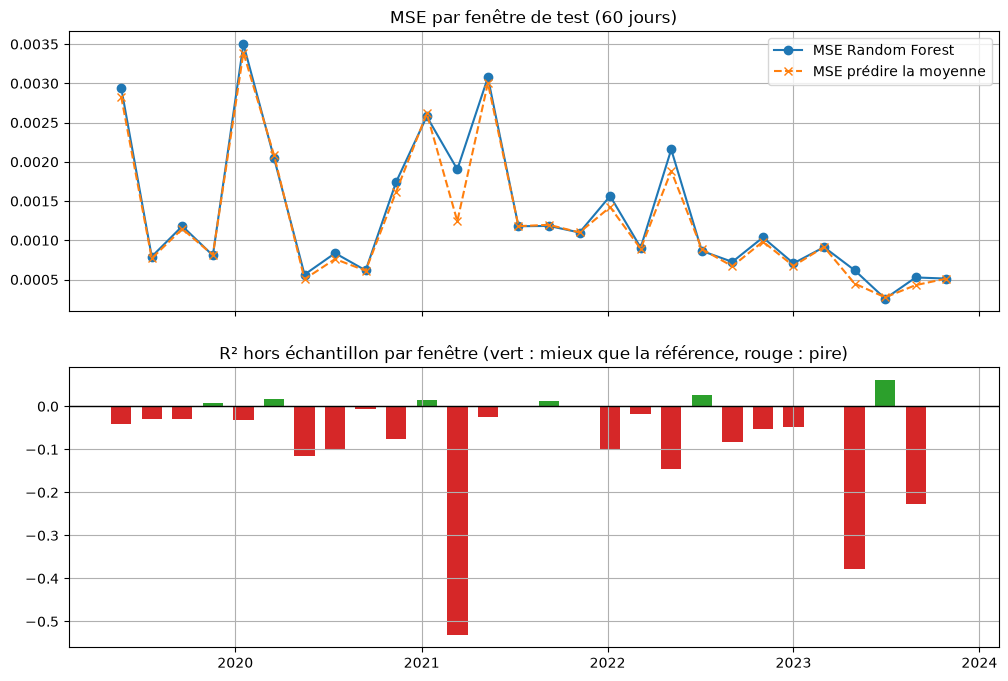

In [62]:
# TODO : tracer l'évolution des performances rolling
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(rolling_scores["début_test"], rolling_scores["MSE_RF"], marker="o", label="MSE Random Forest")
axes[0].plot(rolling_scores["début_test"], rolling_scores["MSE_référence"], marker="x", ls="--", label="MSE prédire la moyenne")
axes[0].set_title("MSE par fenêtre de test (60 jours)")
axes[0].legend()
axes[0].grid(True)

axes[1].bar(rolling_scores["début_test"], rolling_scores["R2_oos"], width=40,
            color=np.where(rolling_scores["R2_oos"] > 0, "tab:green", "tab:red"))
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("R² hors échantillon par fenêtre (vert : mieux que la référence, rouge : pire)")
axes[1].grid(True)

plt.show()

In [63]:
# TODO : moyenne et écart-type des performances
print("MSE moyenne       :", np.mean(rolling_scores["MSE_RF"]))

print("Écart-type de la MSE :", np.std(rolling_scores["MSE_RF"]))

# Bonus : indicateurs relatifs à la référence
print("R² hors échantillon moyen :", round(np.mean(rolling_scores["R2_oos"]), 4))
print("Part des fenêtres où le RF bat la référence : {:.0%}".format(np.mean(rolling_scores["R2_oos"] > 0)))

MSE moyenne       : 0.001315820651963767
Écart-type de la MSE : 0.0008468487626546706
R² hors échantillon moyen : -0.0678
Part des fenêtres où le RF bat la référence : 32%


## Question 22

 **Réponses** (à adapter avec tes graphiques)

**1. Les performances semblent-elles stables ?**
Non. La MSE varie **énormément** d'une fenêtre à l'autre : l'écart-type de la MSE est du même ordre que sa moyenne, voire supérieur, et les fenêtres de crise ont une MSE plusieurs fois plus grande que les fenêtres calmes. Surtout, le **$R^2$ hors échantillon change de signe** selon les périodes : le Random Forest bat la référence sur certaines fenêtres et fait pire sur d'autres, sans régularité. Sa moyenne est proche de 0 ou négative.

**2. Observe-t-on des périodes plus difficiles ?**
Oui : les fenêtres qui contiennent des **crises** ont des MSE très élevées : mars 2020 (Covid), mai-juin 2021 (chute après le pic du printemps), mai-juin 2022 (Terra/Luna, Celsius), novembre 2022 (FTX). Ce sont aussi les périodes où le modèle s'écarte le plus de la référence, dans un sens ou dans l'autre, car ses règles apprises sur une période ne conviennent plus au nouveau régime. Les périodes calmes (comme 2023) ont une MSE faible pour tout le monde. Il faut bien distinguer : une MSE élevée sur une fenêtre traduit d'abord **une période difficile**, pas forcément un mauvais modèle ; c'est le $R^2$ par rapport à la référence qui juge le modèle.

**3. Pourquoi un seul split peut-il être trompeur ?**
- Le résultat dépend fortement de la **période de test choisie** : notre test unique (≈ 2023) est une année calme ; avec un test en 2022, la MSE serait bien plus élevée et le classement des modèles pourrait changer.
- Avec un seul découpage, on n'a **qu'une seule mesure** : impossible de savoir si un petit avantage d'un modèle est réel ou dû au **hasard** de la période.
- En essayant plusieurs modèles ou réglages sur le même test, on finit par en trouver un qui « gagne » par chance : c'est un **surajustement au jeu de test**.

**4. Pourquoi la validation rolling est-elle plus rigoureuse ?**
- Elle **respecte la chronologie** à chaque étape (toujours apprendre sur le passé, tester sur le futur immédiat).
- Elle évalue le modèle sur **de nombreuses périodes** et différents régimes de marché : on mesure la performance **moyenne** et sa **dispersion** (stabilité).
- Elle **simule l'utilisation réelle** d'un modèle en production : réentraîné régulièrement sur les données récentes, puis utilisé sur la période suivante.
- Elle permet de vérifier si un éventuel gain est **systématique** (bat la référence sur la plupart des fenêtres) ou s'il vient d'une seule période favorable.

On pourrait aller plus loin avec une fenêtre **expansive** (on garde tout le passé au lieu des 500 derniers jours) ou avec `sklearn.model_selection.TimeSeriesSplit`, qui implémente ce principe.

---
# Conclusion

Le machine learning temporel consiste à transformer le passé en variables explicatives, apprendre une relation statistique $r_{t+1} \approx f(x_t)$ et l'appliquer au futur.

Ce TP montre que :
- **la performance reste limitée** : sur les rendements journaliers du Bitcoin, ARIMA, le Random Forest et le réseau de neurones font à peu près jeu égal avec des prédicteurs naïfs ($R^2$ hors échantillon proche de 0) ;
- **les modèles flexibles** peuvent capter un peu de structure non linéaire sur certaines périodes, mais ce gain est **instable** dans le temps (validation rolling) ;
- **la validation fait le résultat** : un split aléatoire, un scaler ajusté sur tout le dataset ou une fenêtre glissante centrée peuvent produire des scores flatteurs mais faux ;
- **une bonne performance ne garantit pas la validité** du modèle : en finance, un score anormalement bon est d'abord un signal d'alerte sur une possible fuite d'information.

> En machine learning temporel, comprendre les données et la validation est aussi important que choisir le modèle.